In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
#load the data
df = pd.read_csv('../data/cardekho_dataset.csv', index_col=0)
print(df.shape)
df.head()

(15411, 13)


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [4]:
#check data types, missing values, duplicates
df.info()
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

#check if car_name is just brand + model
print("car_name mismatches:", (df['car_name'] != df['brand'] + ' ' + df['model']).sum())

<class 'pandas.core.frame.DataFrame'>
Index: 15411 entries, 0 to 19543
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  int64  
 4   km_driven          15411 non-null  int64  
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  int64  
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  int64  
 12  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.6+ MB
missing values: 0
duplicate rows: 167
car_name mismatches: 0


### What we learn from the initial checks
- The dataset has **15,411 rows and 13 columns** and **no missing values**, so we don't need to impute anything.
- There are **167 exact duplicate rows**. The same listing was probably scraped twice. If we keep them, a copy of a car could land in the training set while another copy lands in the test set. The model would then be "tested" on cars it has already seen, and our results would look better than they really are.
- `car_name` matches `brand + " " + model` on **every row** (0 mismatches). It's fully redundant, so we drop it.

In [5]:
#drop car_name and duplicate rows
df = df.drop(columns='car_name')
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(15244, 12)


In [6]:
#look for impossible or suspicious values
print(df['seats'].value_counts().sort_index())
print(df['km_driven'].quantile([0.5, 0.9, 0.99, 0.999, 1.0]))

#check the highest km_driven listings
df.sort_values('km_driven', ascending=False)[['brand', 'model', 'vehicle_age', 'km_driven', 'selling_price']].head(12)

seats
0        2
2        7
4       76
5    12767
6      125
7     1902
8      310
9       55
Name: count, dtype: int64
0.500      50000.0
0.900      98000.0
0.990     180000.0
0.999     479757.0
1.000    3800000.0
Name: km_driven, dtype: float64


,brand,model,vehicle_age,km_driven,selling_price
15242,Mahindra,XUV500,5,3800000,1225000
11790,Mercedes-Benz,E-Class,9,1325000,1350000
8701,Toyota,Innova,6,950000,950000
4516,Renault,Duster,4,850000,850000
6673,Volkswagen,Vento,9,830000,380000
10742,Hyundai,Creta,6,825000,825000
11508,Volkswagen,Polo,5,820000,695000
7276,Ford,Ecosport,6,720000,675000
9089,Skoda,Rapid,5,675000,675000
7486,Toyota,Fortuner,2,590000,2850000


### What we learn about outliers
- **2 cars have 0 seats.** That's impossible, so these are data errors.
- **km_driven has an extreme tail.** The median car has 50,000 km and 99% of cars have under 180,000 km, but the max is **3,800,000 km** on a 5-year-old Mahindra XUV500. That's about 2,000 km per day.
- Many of the extreme listings have **km_driven exactly equal to selling_price** (Toyota Innova: 950,000 km and ₹950,000; Renault Duster: 850,000 and 850,000; Hyundai Creta: 825,000 and 825,000). This looks like the seller typed the price into the km field, which tells us these values are entry errors and not real high-mileage cars.
- We remove cars with **more than 500,000 km**. That's 12 rows, about 0.08% of the data. We keep cars between 300k and 500k because many of them are plausible (old Toyota Innovas and Mahindra Boleros are known for running very long distances).
- In the proposal we found that km_driven barely correlated with price (-0.08) and suspected outliers were the reason. This step tests that.

In [7]:
#remove 0-seat cars and impossible km_driven values
df = df[(df['seats'] > 0) & (df['km_driven'] <= 500000)].reset_index(drop=True)
print(df.shape)

(15230, 12)


skew before: 10.11 | skew after: 0.57


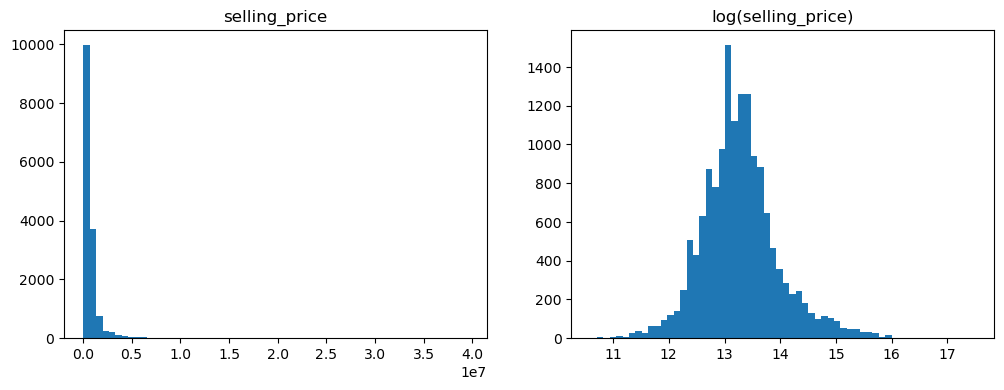

In [8]:
#check the distribution of the outcome variable
df['log_price'] = np.log(df['selling_price'])
print("skew before:", round(df['selling_price'].skew(), 2), "| skew after:", round(df['log_price'].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['selling_price'], bins=60)
axes[0].set_title('selling_price')
axes[1].hist(df['log_price'], bins=60)
axes[1].set_title('log(selling_price)')
plt.show()

### Why we log-transform the price
- `selling_price` is extremely right-skewed (**skew = 10.11**). Most cars sell for a few lakh rupees (median ₹557,500), but a handful of luxury cars go up to ₹39.5M (a Ferrari).
- If we model raw price, the error metric is dominated by those few expensive cars. Missing a Ferrari by ₹2M counts far more than missing a Maruti Alto by ₹50k, even though ₹50k is a bigger mistake relative to an Alto's price.
- After the log transform the skew drops to **0.57**, so the distribution is close to symmetric.
- Working in log terms means errors are **percentage errors**. Being 10% off on a ₹300k car and 10% off on a ₹3M car count the same, which matches how buyers think about a "fair price."

In [9]:
#compare correlations with raw price vs log price
num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
corr = pd.DataFrame({
    'corr_with_price': df[num_cols].corrwith(df['selling_price']),
    'corr_with_log_price': df[num_cols].corrwith(df['log_price'])
}).round(3)
corr.sort_values('corr_with_log_price')

,corr_with_price,corr_with_log_price
vehicle_age,-0.241,-0.486
mileage,-0.305,-0.301
km_driven,-0.118,-0.147
seats,0.115,0.230
engine,0.586,0.654
max_power,0.751,0.759


### What we learn from the correlations
- **The outlier fix worked for km_driven.** Its correlation with price strengthened from -0.08 in our proposal to **-0.118** after cleaning, and to **-0.147** with log price. It's still the weakest predictor, but it now points in the expected direction more clearly.
- **vehicle_age shows the biggest change.** It goes from -0.241 with raw price to **-0.486** with log price. Cars lose value as a *percentage* each year (depreciation), not by a fixed rupee amount. The log scale captures that, and the raw scale hides it.
- **max_power (0.759) and engine (0.654) are still the strongest indicators of price**, consistent with the proposal.
- **mileage is negative (-0.301).** Fuel-efficient cars tend to be small, cheap hatchbacks, while powerful luxury cars use more fuel. So mileage is partly measuring the type of car.

In [10]:
df.to_csv('../data/cardekho_clean.csv', index=False)
print(df.shape)

(15230, 13)


# KNN Regression: Used Car Prices (CarDekho)

In [ ]:
#define features and target, then split 80/20
cat_cols = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
X = df[num_cols + cat_cols]
y = df['log_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(12184, 11) (3046, 11)


### Train/test split
- After cleaning we have **15,230 cars**: **12,184 for training** and **3,046 held out for testing**.
- `random_state=42` makes the split identical every time. **The whole team should use this exact split** so the KNN, linear and tree results can be compared directly.
- The test set is never used for tuning. We choose k with cross-validation on the training set only, and touch the test set once at the very end.

In [ ]:
#compare KNN with and without scaling (k=5, numeric features only)
knn_raw = KNeighborsRegressor(n_neighbors=5).fit(X_train[num_cols], y_train)
pred_raw = knn_raw.predict(X_test[num_cols])

knn_scaled = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=5))])
knn_scaled.fit(X_train[num_cols], y_train)
pred_scaled = knn_scaled.predict(X_test[num_cols])

print("unscaled -> RMSE:", round(np.sqrt(mean_squared_error(y_test, pred_raw)), 4), "R2:", round(r2_score(y_test, pred_raw), 4))
print("scaled   -> RMSE:", round(np.sqrt(mean_squared_error(y_test, pred_scaled)), 4), "R2:", round(r2_score(y_test, pred_scaled), 4))

unscaled -> RMSE: 0.3989 R2: 0.651
scaled   -> RMSE: 0.2102 R2: 0.9031


### Why scaling matters for KNN
- **Without scaling, R² = 0.651. With scaling, R² = 0.903**, and RMSE drops by almost half (0.399 → 0.210). Same model, same k. The only difference is scaling.
- KNN finds "similar" cars by measuring distance. Unscaled, km_driven ranges into the hundreds of thousands while seats ranges from 2 to 9. A 1-seat difference counts the same as a 1-km difference, so km_driven, our *weakest* predictor, ends up deciding which cars count as neighbors.
- Example: a 2-seat sports car and a 7-seat Innova with the same km_driven would look almost identical to unscaled KNN.
- StandardScaler puts every feature on the same scale (mean 0, standard deviation 1), so each one gets a fair say in the distance. Linear regression doesn't need this step, but **KNN does**.

In [ ]:
#build preprocessing: scale numeric, one-hot encode categorical
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

knn_pipe = Pipeline([('prep', preprocessor), ('knn', KNeighborsRegressor())])

#tune k and weighting with 5-fold cross-validation
param_grid = {'knn__n_neighbors': list(range(1, 31)), 'knn__weights': ['uniform', 'distance']}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring='neg_root_mean_squared_error', return_train_score=True, n_jobs=-1)
grid.fit(X_train, y_train)

print("best params:", grid.best_params_)
print("best CV RMSE:", round(-grid.best_score_, 4))

best params: {'knn__n_neighbors': 11, 'knn__weights': 'distance'}
best CV RMSE: 0.1873


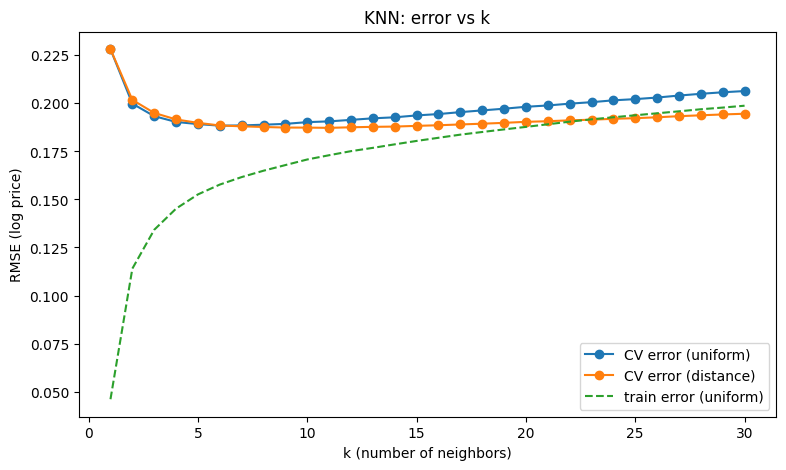

In [ ]:
#plot CV error vs k
results = pd.DataFrame(grid.cv_results_)

plt.figure(figsize=(9, 5))
for w in ['uniform', 'distance']:
    r = results[results['param_knn__weights'] == w].sort_values('param_knn__n_neighbors')
    plt.plot(r['param_knn__n_neighbors'], -r['mean_test_score'], marker='o', label=f'CV error ({w})')

#add training error for uniform to show overfitting
r_uni = results[results['param_knn__weights'] == 'uniform'].sort_values('param_knn__n_neighbors')
plt.plot(r_uni['param_knn__n_neighbors'], -r_uni['mean_train_score'], linestyle='--', label='train error (uniform)')

plt.xlabel('k (number of neighbors)')
plt.ylabel('RMSE (log price)')
plt.title('KNN: error vs k')
plt.legend()
plt.show()

### What we learn from tuning k (the bias-variance tradeoff)
- **Best model: k = 11 with distance weighting, CV RMSE = 0.1873.**
- **k = 1 overfits.** Training error is almost zero (0.047) but CV error is the worst (0.229). Each car is priced by copying its single closest match, so the model memorizes noise. That's high variance.
- **As k grows, training error rises but CV error falls**, down to about 0.189 at k = 5 for uniform weights. Averaging over more neighbors smooths out quirks in individual listings.
- **Past the sweet spot, CV error climbs again** (uniform: 0.198 at k = 20, 0.206 at k = 30). With too many neighbors, a Honda City gets averaged with cars that aren't really comparable. That's high bias.
- **Distance weighting wins** because the closest neighbors count more. That keeps the error curve flatter at large k, since far-away cars get little say. Note: with distance weighting the *training* error is near zero for any k, because each training car is its own nearest neighbor at distance 0. That's why we only trust CV error for choosing k.

In [ ]:
#compare feature sets to see what each group of variables adds
feature_sets = {
    'numeric only': [],
    '+ seller/fuel/transmission': ['seller_type', 'fuel_type', 'transmission_type'],
    '+ brand': ['brand', 'seller_type', 'fuel_type', 'transmission_type'],
    '+ brand + model': ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type'],
}

comparison = []
for name, cats in feature_sets.items():
    steps = [('num', StandardScaler(), num_cols)]
    if cats:
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore'), cats))
    pipe = Pipeline([('prep', ColumnTransformer(steps)), ('knn', KNeighborsRegressor(weights='distance'))])
    g = GridSearchCV(pipe, {'knn__n_neighbors': list(range(1, 31))}, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    g.fit(X_train[num_cols + cats], y_train)
    comparison.append({'features': name, 'best_k': g.best_params_['knn__n_neighbors'], 'cv_rmse': round(-g.best_score_, 4)})

pd.DataFrame(comparison)

,features,best_k,cv_rmse
0,numeric only,8,0.2111
1,+ seller/fuel/transmission,8,0.2071
2,+ brand,9,0.1983
3,+ brand + model,11,0.1873


### What we learn from the feature comparison
| Features | Best k | CV RMSE |
|---|---|---|
| numeric only | 8 | 0.2111 |
| + seller/fuel/transmission | 8 | 0.2071 |
| + brand | 9 | 0.1983 |
| + brand + model | 11 | 0.1873 |

- **The 6 numeric features do most of the work.** Age, power, engine size and so on already get KNN to an RMSE of 0.211.
- **Seller, fuel and transmission add very little** (0.211 → 0.207). They're probably already captured by the numeric features. Automatic cars, for example, tend to have higher max_power anyway.
- **Brand and model add the most on top of that** (0.207 → 0.187). Two cars can have identical specs but different prices because of the badge. Toyota and Mahindra hold resale value better than other brands, which matches the boxplot in our proposal.
- **Adding `model` helped even though it adds about 120 dummy columns.** We expected it might hurt, since too many columns make distances less meaningful (the curse of dimensionality). But a model mismatch adds a fixed amount to the distance, so KNN effectively looks for **the same model first**, then matches on age and km. That's exactly how a person would price a used car: "find other 2018 Honda Citys and compare."

In [ ]:
#evaluate the best model on the test set
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

#convert back to rupees for interpretable errors
actual_price = np.exp(y_test)
pred_price = np.exp(y_pred)
test_mae = mean_absolute_error(actual_price, pred_price)
test_mape = np.mean(np.abs(pred_price - actual_price) / actual_price)

#baseline: always guess the average training price
baseline_pred = np.full(len(y_test), y_train.mean())

print("KNN      -> RMSE (log):", round(test_rmse, 4), "| R2:", round(test_r2, 4), "| MAE (Rs):", round(test_mae), "| MAPE:", round(test_mape * 100, 1), "%")
print("baseline -> RMSE (log):", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 4), "| MAE (Rs):", round(mean_absolute_error(actual_price, np.exp(baseline_pred))))

KNN      -> RMSE (log): 0.1844 | R2: 0.9254 | MAE (Rs): 95856 | MAPE: 13.9 %
baseline -> RMSE (log): 0.6754 | MAE (Rs): 383102


### Test set results
- **Test RMSE = 0.1843, R² = 0.9255.** KNN explains about 93% of the variation in log price on cars it has never seen.
- **Test RMSE (0.184) is close to CV RMSE (0.187)**, so cross-validation gave an honest estimate and we didn't overfit while choosing k.
- In rupees, the **mean absolute error is about ₹95,800** and the **average error is 13.9%** of the car's price. An RMSE of 0.184 in log terms means a typical estimate is within roughly ±20%.
- **Compared with the baseline** of guessing the average price for every car (RMSE 0.675, MAE ₹383,100), KNN cuts the error by about **75%**.

In [ ]:
#break down errors by price segment and brand
errors = pd.DataFrame({
    'brand': X_test['brand'].values,
    'model': X_test['model'].values,
    'actual': actual_price.values,
    'predicted': pred_price
})
errors['pct_error'] = np.abs(errors['predicted'] - errors['actual']) / errors['actual']
errors['price_segment'] = pd.qcut(errors['actual'], 4, labels=['Q1 (cheapest)', 'Q2', 'Q3', 'Q4 (priciest)'])

print(errors.groupby('price_segment', observed=True).agg(median_price=('actual', 'median'), mape=('pct_error', 'mean')).round(3))

#brands with at least 10 test cars
brand_err = errors.groupby('brand').agg(n=('pct_error', 'size'), mape=('pct_error', 'mean')).round(3)
print(brand_err[brand_err['n'] >= 10].sort_values('mape', ascending=False))

print("within 10%:", round((errors['pct_error'] <= 0.10).mean() * 100, 1), "% | within 20%:", round((errors['pct_error'] <= 0.20).mean() * 100, 1), "%")

               median_price   mape
price_segment                     
Q1 (cheapest)      295000.0  0.198
Q2                 465000.0  0.128
Q3                 666000.0  0.109
Q4 (priciest)     1200000.0  0.121
                  n   mape
brand                     
Land Rover       11  0.205
Jaguar           14  0.179
Mercedes-Benz    58  0.178
Volkswagen      138  0.170
Datsun           28  0.162
Skoda            60  0.161
Mahindra        201  0.157
Tata             85  0.157
Ford            164  0.147
Toyota          161  0.140
Hyundai         590  0.136
Audi             33  0.135
BMW              78  0.130
Maruti         1017  0.129
Honda           273  0.128
Renault         101  0.128
within 10%: 48.3 % | within 20%: 77.6 %


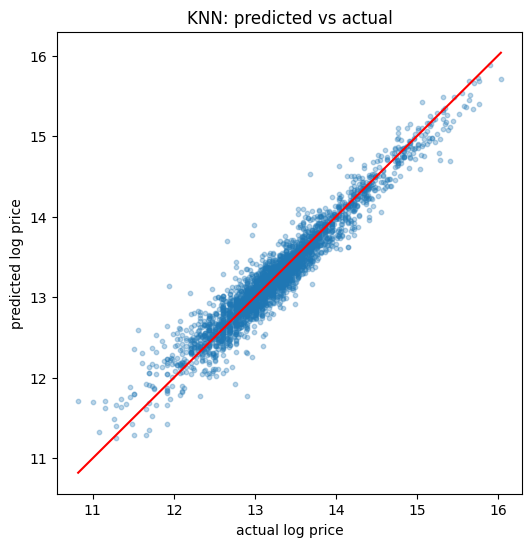

In [ ]:
#plot predicted vs actual
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('actual log price')
plt.ylabel('predicted log price')
plt.title('KNN: predicted vs actual')
plt.show()

### Where KNN struggles
- **48.3% of cars are priced within 10% and 77.6% within 20%.** For a fair-price benchmark, that means about 3 in 4 estimates are usable as a starting point.
- **Cheap cars have the highest percentage error (19.8%** in the cheapest quarter, median ₹295k, compared with 11–13% elsewhere). For old budget cars, condition and accident history matter a lot, and our data doesn't capture them. A ₹40k mistake is also a large share of a ₹295k car.
- **Expensive cars have the largest rupee errors.** All of the five biggest misses are luxury cars (Land Rover, Porsche, Volvo) underpriced by ₹1.9M–2.6M.
- **Luxury brands are the hardest: Land Rover 20.5%, Jaguar 17.9%, Mercedes-Benz 17.8%.** Mass-market brands do best: Maruti 12.9%, Honda 12.8%, Renault 12.8%. KNN can only be as good as its neighbors. There are over a thousand Marutis in the test set alone, but only a handful of comparable Land Rovers, so KNN has to borrow neighbors that aren't true matches.
- This is a limitation of KNN: **it can't extrapolate** and does worst where the data is sparse. It'll be worth checking whether tree models or linear models handle the luxury segment better.

In [ ]:
#summary row for the team results table
knn_summary = pd.DataFrame([{
    'model': f"KNN (k={grid.best_params_['knn__n_neighbors']}, {grid.best_params_['knn__weights']})",
    'cv_rmse_log': round(-grid.best_score_, 4),
    'test_rmse_log': round(test_rmse, 4),
    'test_r2': round(test_r2, 4),
    'test_mae_rupees': round(test_mae)
}])
knn_summary

,model,cv_rmse_log,test_rmse_log,test_r2,test_mae_rupees
0,"KNN (k=11, distance)",0.1873,0.1844,0.9254,95856


### KNN conclusions
- **Final KNN: k = 11, distance-weighted. Test RMSE 0.184 (log), R² 0.926, MAE ₹95,800.** This is the benchmark the linear and tree models need to beat on the same split.
- **Cleaning decisions mattered.** Removing duplicates prevents leakage between train and test, removing the impossible km values recovered the km_driven relationship, and the log transform revealed that depreciation is the second strongest signal after power.
- **Scaling isn't optional for KNN.** It changed R² from 0.65 to 0.90 with nothing else changed.
- **KNN works like a used-car appraiser.** It finds the same model and adjusts for age and usage, which is why it performs well on common cars.
- **Its weakness is rare, expensive cars** with few comparable listings, and that's where a buyer most needs a fair benchmark. For the final presentation, we should compare how each model does on the luxury segment, not just overall.
- KNN also **can't tell us *why* a car is worth what it is**. It gives no coefficients and no feature importances. To answer the question "what drives the price of a used car?", we need the linear model coefficients and the tree feature importances.

## What We Learned from KNN

### Model results
- **KNN works well overall.** The test R² was **0.926**, so it explains about 93% of the variation in price. The typical error is about **₹95,800**, or **13.9%** of a car's price.
- **It beats the baseline by a lot.** Guessing the average price for every car gives an error of ₹383,100, so KNN cuts the error by about **75%**.
- **We can trust the results.** The test error (**0.184**) is close to the CV error (**0.187**), so we didn't overfit while choosing k.
- **Scaling is essential.** The same model scored **R² 0.65 without scaling and 0.90 with it**. Without scaling, km_driven decides which cars count as "similar."
- **The best setting is k = 11 with distance weighting.** k = 1 overfits (it memorizes individual cars), and very large k underfits (it averages cars that aren't comparable). That's the **bias-variance tradeoff**.
- **Brand and model add the most.** Specs alone got RMSE to **0.211**, and adding brand and model brought it to **0.187**. Seller, fuel and transmission added almost nothing.
- **KNN prices cars the way an appraiser does.** It finds the same model, then adjusts for age and km.
- **About 3 in 4 cars are priced within 20%**, and about half within 10%.
- **Its weak spots are cheap cars** (**19.8%** error, since condition matters and we don't have data on it) **and luxury brands** (Land Rover **20.5%**, Jaguar **17.9%**). There are too few comparable luxury listings to use as neighbors.
- **It can't explain why a car is priced the way it is.** KNN gives no coefficients or feature importances, so the linear and tree models will have to answer *"what drives price."*

### Cleaning lessons
- **Removing 167 duplicates** keeps the same car from appearing in both the training and test sets.
- **Removing impossible km values** strengthened km_driven's correlation from **-0.08 to -0.12**. Some of them had km equal to the price, which points to entry errors.
- **The log transform fixed the extreme skew** (**10.1 → 0.57**) and showed that vehicle age matters much more than it first appeared (**-0.24 → -0.49**).